# Predictive Maintenance: Data Understanding


In [33]:
import pandas as pd

df = pd.read_csv('data/ai4i2020.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [34]:
df.shape

(10000, 14)

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [36]:
df['Machine failure'].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [37]:
df['Machine failure'].value_counts(normalize=True) * 100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

The failure rate is low, but it is still an important proportion. We want to detect failures early so we can fix the machine before it breaks down.

In [38]:
sensors = ['Air temperature [K]', 'Process temperature [K]',
           'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

df.groupby('Machine failure')[sensors].mean()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


Machines that failed had clearly higher torque and tool wear, and their rotational speed was lower. This may be due to the relationship between torque and speed, but it needs to be verified. The difference in air and process temperature is small, possibly because the machine is designed to withstand high temperatures.

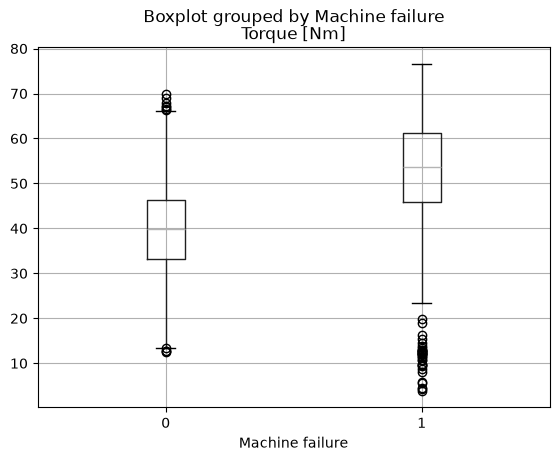

In [39]:
import matplotlib.pyplot as plt

df.boxplot(column='Torque [Nm]', by='Machine failure')
plt.show()

In [40]:
df.groupby('Machine failure')['Torque [Nm]'].describe()

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,9661.0,39.629655,9.472080,12.6,33.10,39.9,46.3,70.0
1,339.0,50.168142,16.374498,3.8,45.95,53.7,61.2,76.6


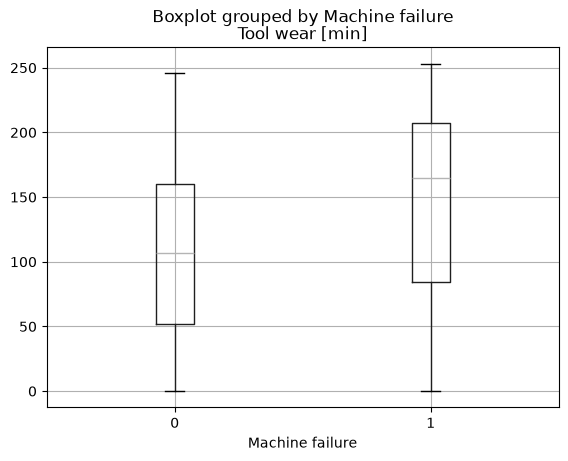

In [41]:
df.boxplot(column='Tool wear [min]', by='Machine failure')
plt.show()

In [42]:
df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum()

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

In [43]:
modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
pd.crosstab(df['Machine failure'], df[modes].sum(axis=1))

col_0,0,1,2,3
Machine failure,,,,
0,9643,18,0,0
1,9,306,23,1


In [44]:
df['TWF'].head(3)
df[['TWF']].head(3)

,TWF
0,0
1,0
2,0


In [45]:
print(df['TWF'].head(3))
df[['TWF']].head(3)

0    0
1    0
2    0
Name: TWF, dtype: int64


,TWF
0,0
1,0
2,0


In [46]:
mask = (df['Machine failure'] == 0) & (df[modes].sum(axis=1) > 0)
df[mask][modes].sum()

TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64

In [47]:
mask2 = (df['Machine failure'] == 1) & (df[modes].sum(axis=1) == 0)
df[mask2]

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
1437,1438,H30851,H,298.8,309.9,1439,45.2,40,1,0,0,0,0,0
2749,2750,M17609,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0
4044,4045,M18904,M,301.9,310.9,1419,47.7,20,1,0,0,0,0,0
4684,4685,M19544,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
5536,5537,M20396,M,302.3,311.8,1363,54.0,119,1,0,0,0,0,0
5941,5942,L53121,L,300.6,310.7,1438,48.5,78,1,0,0,0,0,0
6478,6479,L53658,L,300.5,309.8,1663,29.1,145,1,0,0,0,0,0
8506,8507,L55686,L,298.4,309.6,1710,27.3,163,1,0,0,0,0,0
9015,9016,L56195,L,297.2,308.1,1431,49.7,210,1,0,0,0,0,0


## Data Quality Summary

- Size: 10,000 records and 14 columns.
- Missing values: none. All columns are fully populated.
- Synthetic data: according to the UCI page, this dataset is synthetic and designed to reflect real industrial predictive maintenance data.
- Class imbalance: only 339 records (3.39%) are failures, so accuracy alone would be a misleading metric.
- Failure modes: most failures (306) have a single recorded mode, while 24 have two or more.
- Inconsistencies found:
  - 18 records have an RNF (random failure) flag but `Machine failure = 0`.
  - 9 records have `Machine failure = 1` but no failure mode recorded.
- Next steps: the failure-mode columns (TWF, HDF, PWF, OSF, RNF) reveal the target, so they will be excluded from the model inputs to avoid data leakage.